In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
import pickle
from hypergraphx import Hypergraph

from src.utils import hyperedge_homogeneity_list, hypergraph_disjointness

In [86]:
# All HyperLap datasets: hyperedge homogeneity + basic hypergraph stats
DATASET_DIR = Path("data/real").resolve()

homogeneity_by_dataset: dict = {}

for txt_path in sorted(DATASET_DIR.glob("*_graph.txt")):
    key = txt_path.stem.replace("_graph", "")
    print(f"Processing: {key}")
    
    edge_list = []
    with open(txt_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens = line.replace(",", " ").split()
            edge_list.append([int(x) for x in tokens])
    
    H = Hypergraph(edge_list)
    
    n_nodes = len(H.get_nodes())
    n_edges = len(H.get_edges())

    deg_dist = H.degree_distribution()
    mean_node_degree = float(sum(deg * cnt for deg, cnt in deg_dist.items()) / n_nodes)

    edge_sizes = H.get_sizes()
    mean_hyperedge_size = float(np.mean(edge_sizes)) if len(edge_sizes) > 0 else float("nan")

    hom_list = hyperedge_homogeneity_list(H)
    disjointness = hypergraph_disjointness(H)
    
    homogeneity_by_dataset[key] = {
        "H": H,
        "path": str(txt_path),
        "n_nodes": len(H.get_nodes()),
        "n_edges": len(H.get_edges()),
        "mean_node_degree": mean_node_degree,
        "mean_hyperedge_size": mean_hyperedge_size,
        "min_hyperedge_size": min(edge_sizes),
        "max_hyperedge_size": max(edge_sizes),
        "hyperedge_homogeneity": hom_list,
        "mean_homogeneity": np.mean(hom_list),
        "median_homogeneity": np.median(hom_list),
        "std_homogeneity": np.std(hom_list),
        "disjointness": disjointness
    }


Processing: contact-high
Processing: contact-primary
Processing: email-Enron-full
Processing: email-Eu-full


In [90]:
names = list(homogeneity_by_dataset.keys())
n = len(names)

for i, name in enumerate(names):
    print(f"{name}:")
    print(f"    n_edges={homogeneity_by_dataset[name]['n_edges']}, n_nodes={homogeneity_by_dataset[name]['n_nodes']}")
    print(f"    mean_hyperedge_size={round(homogeneity_by_dataset[name]['mean_hyperedge_size'], 2)}, mean_node_degree={round(homogeneity_by_dataset[name]['mean_node_degree'], 2)}")
    print(f"    mean_homogeneity: {round(homogeneity_by_dataset[name]['mean_homogeneity'], 2)}, disjointness: {round(homogeneity_by_dataset[name]['disjointness'], 5)}")


contact-high:
    n_edges=7818, n_nodes=327
    mean_hyperedge_size=2.33, mean_node_degree=55.63
    mean_homogeneity: 3.48, disjointness: 0.00074
contact-primary:
    n_edges=12704, n_nodes=242
    mean_hyperedge_size=2.42, mean_node_degree=126.98
    mean_homogeneity: 5.03, disjointness: 0.0008
email-Enron-full:
    n_edges=1459, n_nodes=143
    mean_hyperedge_size=3.13, mean_node_degree=31.94
    mean_homogeneity: 9.23, disjointness: 0.01627
email-Eu-full:
    n_edges=24520, n_nodes=986
    mean_hyperedge_size=3.62, mean_node_degree=90.04
    mean_homogeneity: 25.81, disjointness: 0.00408


contact-high:
    n_edges=7818, n_nodes=327
    mean_homogeneity: 3.48, disjointness: 0.074
    homogeneity/disjointness: 4709
contact-primary:
    n_edges=12704, n_nodes=242
    mean_homogeneity: 5.03, disjointness: 0.08
    homogeneity/disjointness: 6313
email-Enron-full:
    n_edges=1459, n_nodes=143
    mean_homogeneity: 9.23, disjointness: 1.627
    homogeneity/disjointness: 567
email-Eu-full:
    n_edges=24520, n_nodes=986
    mean_homogeneity: 25.81, disjointness: 0.408
    homogeneity/disjointness: 6320
Saved: results/images/real_homogeneity.png


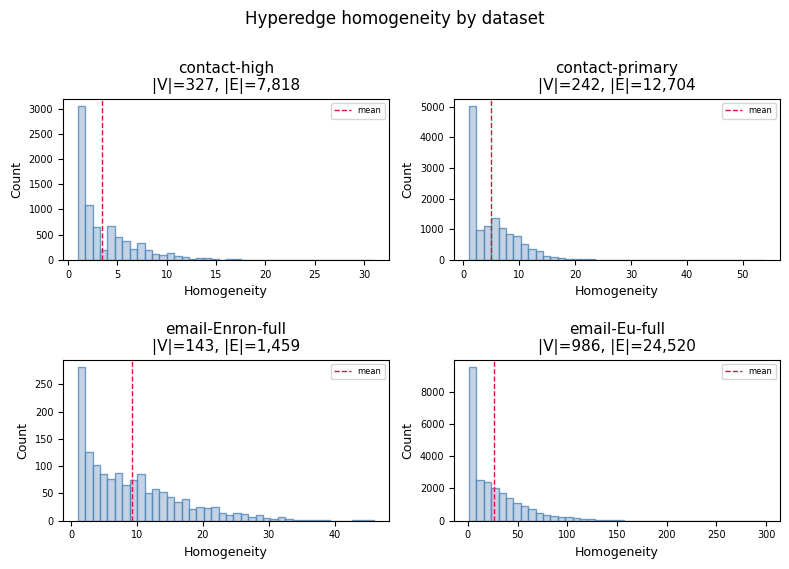

In [84]:
names = list(homogeneity_by_dataset.keys())
n = len(names)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(8, 6), squeeze=False)
axes_flat = axes.ravel()

for i, name in enumerate(names):
    ax = axes_flat[i]
    hom = homogeneity_by_dataset[name]["hyperedge_homogeneity"]
    ax.hist(hom, bins=40, edgecolor="steelblue", alpha=0.75, color="lightsteelblue")
    mu = float(homogeneity_by_dataset[name]["mean_homogeneity"])
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1, label="mean")
    ax.legend(fontsize=6, loc="best")
    ax.set_title(
        f"{name}\n|V|={homogeneity_by_dataset[name]['n_nodes']:,}, |E|={homogeneity_by_dataset[name]['n_edges']:,}",
        fontsize=11,
    )
    ax.set_xlabel("Homogeneity", fontsize=9)
    ax.set_ylabel("Count", fontsize=9)
    ax.tick_params(labelsize=7)
    print(f"{name}:")
    print(f"    n_edges={homogeneity_by_dataset[name]['n_edges']}, n_nodes={homogeneity_by_dataset[name]['n_nodes']}")
    print(f"    mean_homogeneity: {round(homogeneity_by_dataset[name]['mean_homogeneity'], 2)}, disjointness: {round(homogeneity_by_dataset[name]['disjointness']*100, 3)}")
    print(f"    homogeneity/disjointness: {homogeneity_by_dataset[name]['mean_homogeneity'] / homogeneity_by_dataset[name]['disjointness']:.0f}")

for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle("Hyperedge homogeneity by dataset", fontsize=12, y=0.94)

fig.tight_layout(rect=[0, 0, 1, 0.935])
fig.subplots_adjust(hspace=0.62, wspace=0.20)

out_dir = Path("results/images")
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "real_homogeneity.png"
fig.savefig(out_path, dpi=300)
print(f"Saved: {out_path}")

plt.show()

## Synthetic datasets homogeneity (`data/synthetic`)

Compute the same homogeneity/disjointness statistics for all generated synthetic graphs.

In [ ]:
synthetic_dir = Path("results/walk_exploration").resolve()
synthetic_paths = sorted(synthetic_dir.glob("hypergraphs*.pkl"))

synthetic_rows = []
# For plotting: one pooled homogeneity list per file (all edges from all graphs).
synthetic_homogeneity = {}

for pkl_path in synthetic_paths:
    with open(pkl_path, "rb") as f:
        graphs = pickle.load(f)

    key = pkl_path.stem

    pooled_hom = []
    per_graph_nodes = []
    per_graph_edges = []
    per_graph_mean_node_degree = []
    per_graph_disjointness = []
    per_graph_edge_sizes = []
    per_graph_max_edge_sizes = []

    for obj in graphs:
        H = obj
        if "ncom2" in str(pkl_path):
            H = H[0]

        hom_list = hyperedge_homogeneity_list(H)
        edge_sizes = [len(e) for e in H.get_edges()]

        n_nodes = len(H.get_nodes())
        n_edges = len(H.get_edges())

        deg_dist = H.degree_distribution()
        mean_node_degree = float(sum(deg * cnt for deg, cnt in deg_dist.items()) / n_nodes)

        pooled_hom.extend(hom_list)
        per_graph_nodes.append(n_nodes)
        per_graph_edges.append(n_edges)
        per_graph_mean_node_degree.append(mean_node_degree)
        per_graph_disjointness.append(float(hypergraph_disjointness(H)))
        if len(edge_sizes) > 0:
            per_graph_edge_sizes.append(float(np.mean(edge_sizes)))
            per_graph_max_edge_sizes.append(np.max(edge_sizes))

    if len(pooled_hom) == 0:
        print(f"Skipped (no readable hypergraphs): {pkl_path}")
        continue

    synthetic_homogeneity[key] = pooled_hom
    
    synthetic_rows.append(
        {
            "dataset": key,
            "path": str(pkl_path.relative_to(Path.cwd())),
            "n_graphs": len(per_graph_nodes),
            "median_n_nodes": float(np.median(per_graph_nodes)),
            "median_n_edges": float(np.median(per_graph_edges)),
            "mean_node_degree": float(np.mean(per_graph_mean_node_degree)),
            "mean_homogeneity": float(np.mean(pooled_hom)),
            "median_homogeneity": float(np.median(pooled_hom)),
            "std_homogeneity": float(np.std(pooled_hom)),
            "mean_edge_size": float(np.mean(per_graph_edge_sizes)),
            "max_edge_size": float(np.max(per_graph_max_edge_sizes)),
            "mean_disjointness": float(np.mean(per_graph_disjointness)),
        }
    )

synthetic_df = (
    pd.DataFrame(synthetic_rows)
    .sort_values(["mean_homogeneity", "dataset"], ascending=[False, True])
    .reset_index(drop=True)
)

display(synthetic_df)

n = len(synthetic_df)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows), squeeze=False)
axes = axes.ravel()

for i, name in enumerate(synthetic_df["dataset"].tolist()):
    ax = axes[i]
    hom = synthetic_homogeneity[name]
    ax.hist(hom, bins=30, edgecolor="steelblue", alpha=0.75, color="lightsteelblue")
    mu = float(np.mean(hom))
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, label="mean")
    row = synthetic_df[synthetic_df["dataset"] == name].iloc[0]
    ax.set_title(
        f"{name}\n#graphs={int(row['n_graphs'])}, median |V|={row['median_n_nodes']:.1f}",
        fontsize=9,
    )
    ax.set_xlabel("Hyperedge homogeneity")
    ax.set_ylabel("Count")
    ax.legend(fontsize=7, loc="best")

for j in range(n, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Synthetic files: homogeneity distributions", fontsize=12)
plt.tight_layout()
plt.show()

TypeError: 'float' object is not iterable

In [ ]:
synthetic_df.iloc[[4, 2, 5, 0, 3, 1]].round(2)

,dataset,path,n_graphs,median_n_nodes,median_n_edges,mean_node_degrees,mean_homogeneity,median_homogeneity,std_homogeneity,mean_edge_size,max_edge_size,mean_disjointness
4,hypergraphs_ncom1_avgdeg5,results/walk_exploration/hypergraphs_ncom1_avg...,5,493.0,736.0,208.73,1.04,1.00,0.16,3.46,15.0,0.0
2,hypergraphs_ncom1_avgdeg20,results/walk_exploration/hypergraphs_ncom1_avg...,5,500.0,2199.0,375.99,1.45,1.33,0.50,4.61,50.0,0.0
5,hypergraphs_ncom2_avgdeg5_aff09,results/walk_exploration/hypergraphs_ncom2_avg...,5,494.0,713.0,203.05,1.04,1.00,0.15,3.47,15.0,0.0
0,hypergraphs_ncom2_avgdeg20_aff09,results/walk_exploration/hypergraphs_ncom2_avg...,5,500.0,2185.0,380.06,1.47,1.36,0.51,4.67,50.0,0.0
3,hypergraphs_ncom2_avgdeg5_aff06,results/walk_exploration/hypergraphs_ncom2_avg...,5,495.0,726.0,217.81,1.04,1.00,0.17,3.47,15.0,0.0
1,hypergraphs_ncom2_avgdeg20_aff06,results/walk_exploration/hypergraphs_ncom2_avg...,5,500.0,2207.0,379.86,1.46,1.33,0.51,4.62,50.0,0.0


## Node degree and hyperedge size distributions

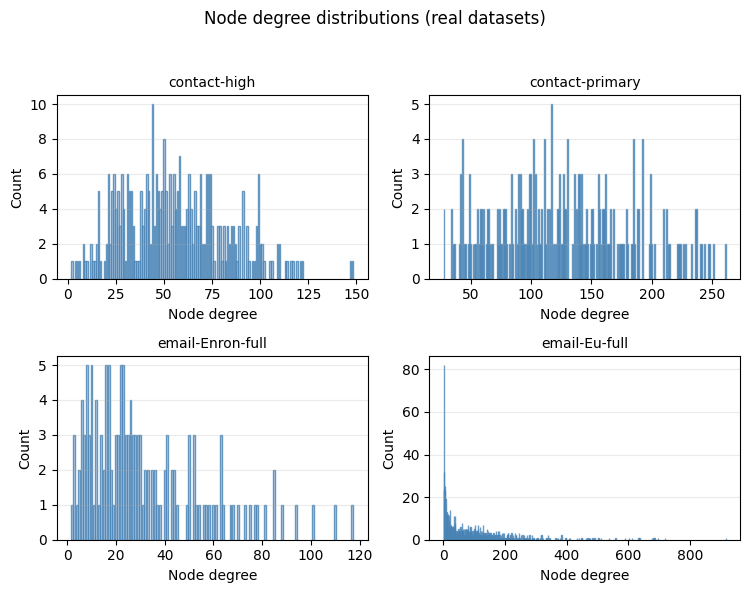

In [66]:
# Node degree distributions (one subplot per real dataset)
real_names = list(homogeneity_by_dataset.keys())

n = len(real_names)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.8 * ncols, 3.0 * nrows), squeeze=False)
axes = axes.ravel()

for i, name in enumerate(real_names):
    ax = axes[i]
    H = homogeneity_by_dataset[name]["H"]

    deg_dist = H.degree_distribution()  # dict: degree -> count
    degrees = np.array(sorted(deg_dist.keys()), dtype=int)
    counts = np.array([deg_dist[d] for d in degrees], dtype=float)
    probs = counts

    ax.bar(degrees, probs, color="lightsteelblue", edgecolor="steelblue", alpha=0.8)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Node degree")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.25)

for j in range(n, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Node degree distributions (real datasets)", fontsize=12, y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

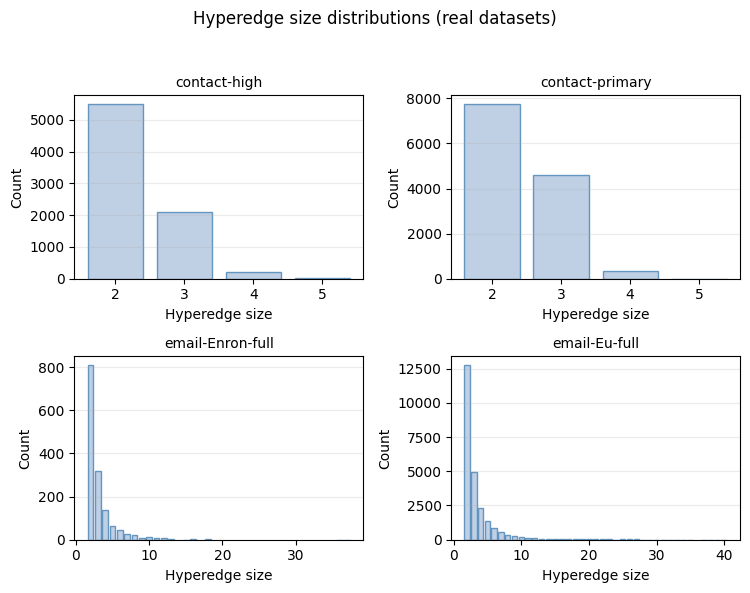

In [65]:
# Hyperedge size distributions (one subplot per real dataset)
real_names = list(homogeneity_by_dataset.keys())

n = len(real_names)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.8 * ncols, 3.0 * nrows), squeeze=False)
axes = axes.ravel()

for i, name in enumerate(real_names):
    ax = axes[i]
    H = homogeneity_by_dataset[name]["H"]

    sizes = np.array(H.get_sizes(), dtype=int)
    unique_sizes, counts = np.unique(sizes, return_counts=True)
    probs = counts

    ax.bar(unique_sizes, probs, color="lightsteelblue", edgecolor="steelblue", alpha=0.8)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Hyperedge size")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.25)

for j in range(n, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Hyperedge size distributions (real datasets)", fontsize=12, y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()